# 01 · 9-state quadrotor dynamics

> **In short:** the ODE track models the quadrotor with 9 states and 4 attitude-level commands. This notebook simulates the package model directly and checks two physical facts: hover is an equilibrium and pitch produces a drag-limited forward speed.
>
> **Runtime:** a few seconds · **Read alongside:** [Theory 02 · Dynamics](../1.Docs/Theory/02_Quadrotor_Dynamics.md) · [Model conventions](../2.Code/docs/concepts/conventions.md)

**You will:**

- load the model used by the controller from `config/controller.yaml`
- verify the hover equilibrium
- compare forward flight with the analytic steady-state speed

## The model

State and command:

$$\mathbf{x}=[x,y,z,v_x,v_y,v_z,\phi,\theta,\psi]^T,\qquad \mathbf{u}=[\phi_c,\theta_c,v_{z,c},\dot\psi_c]^T$$

Horizontal acceleration comes from tilting the thrust, with linear drag $k_D$:

$$\dot{\mathbf v}_{xy}=\mathbf R_Z(\psi)\begin{bmatrix}g\,F_\theta\\-g\,F_\phi\end{bmatrix}-k_D\mathbf v_{xy}$$

where $F_\theta, F_\phi$ are the normalized tilt factors ($F_\theta=\tan\theta$ when $\phi=0$).
Attitude and climb rate follow first-order lags:

$$\dot\phi=\frac{k_\phi\phi_c-\phi}{\tau_\phi},\quad \dot\theta=\frac{k_\theta\theta_c-\theta}{\tau_\theta},\quad \dot v_z=\frac{k_{v_z}v_{z,c}-v_z}{\tau_{v_z}},\quad \dot\psi=\dot\psi_c$$

The implementation is `quadrotor_mpc.control.ccmpc.dynamics`; integration uses RK4.

In [1]:
from nbsetup import *

In [2]:
from quadrotor_mpc.control.ccmpc.dynamics import QuadrotorDynamics

dynamics = QuadrotorDynamics.from_config(str(CONFIG / "controller.yaml"))
dt = 0.06  # controller timestep in config/controller.yaml
print({name: getattr(dynamics, name) for name in ("g", "kD", "k_phi", "k_theta", "k_vz", "tau_phi", "tau_theta", "tau_vz")})


def rollout(x0, u, steps):
    states = [np.asarray(x0, dtype=float)]
    for _ in range(steps):
        states.append(dynamics.discrete(states[-1], np.asarray(u, dtype=float), dt))
    return np.arange(steps + 1) * dt, np.array(states)

{'g': 9.81, 'kD': 0.5, 'k_phi': 1.0, 'k_theta': 1.0, 'k_vz': 3.0, 'tau_phi': 0.33, 'tau_theta': 0.33, 'tau_vz': 0.4}


## Hover is an equilibrium

With zero tilt and zero commands every derivative is zero, so the state must not move.

In [3]:
t, hover = rollout(np.zeros(9), np.zeros(4), steps=100)
print("largest state change over 6 s:", np.abs(hover - hover[0]).max())
assert np.allclose(hover, 0.0)

largest state change over 6 s: 0.0


## Pitch produces a drag-limited forward speed

Commanding $\theta_c$ tilts the vehicle to $k_\theta\theta_c$ after the attitude lag. In steady state
thrust tilt balances drag:

$$v_x^{\infty}=\frac{g\tan(k_\theta\theta_c)}{k_D}$$

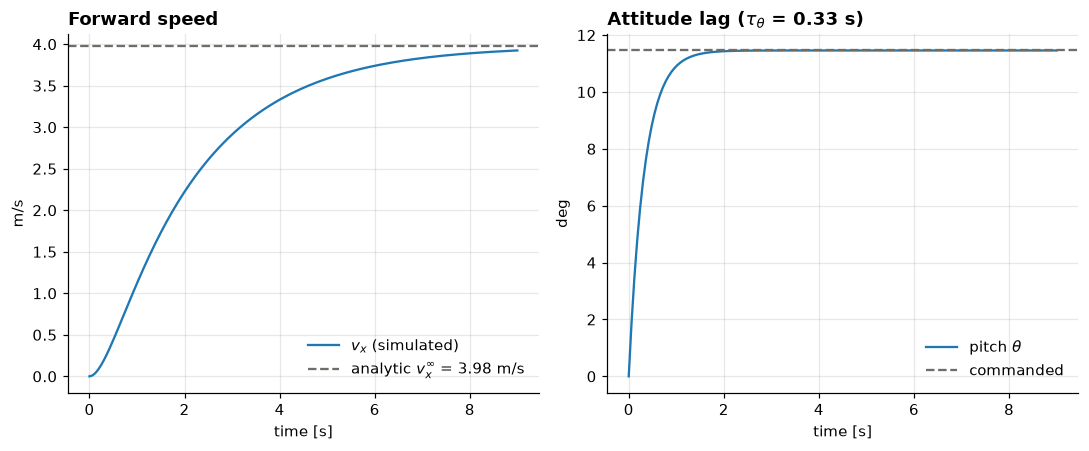

final v_x = 3.924 m/s, analytic 3.977 m/s


In [4]:
theta_c = 0.2  # rad, about 11.5 degrees
t, forward = rollout(np.zeros(9), [0.0, theta_c, 0.0, 0.0], steps=150)
v_inf = dynamics.g * np.tan(dynamics.k_theta * theta_c) / dynamics.kD

fig, (ax_v, ax_att) = plt.subplots(1, 2)
ax_v.plot(t, forward[:, 3], label="$v_x$ (simulated)")
ax_v.axhline(v_inf, color=NEUTRAL, ls="--", label=f"analytic $v_x^\\infty$ = {v_inf:.2f} m/s")
ax_v.set(title="Forward speed", xlabel="time [s]", ylabel="m/s")
ax_v.legend()
ax_att.plot(t, np.rad2deg(forward[:, 7]), label="pitch $\\theta$")
ax_att.axhline(np.rad2deg(dynamics.k_theta * theta_c), color=NEUTRAL, ls="--", label="commanded")
ax_att.set(title=f"Attitude lag ($\\tau_\\theta$ = {dynamics.tau_theta} s)", xlabel="time [s]", ylabel="deg")
ax_att.legend()
plt.tight_layout()
plt.show()
print(f"final v_x = {forward[-1, 3]:.3f} m/s, analytic {v_inf:.3f} m/s")
assert abs(forward[-1, 3] - v_inf) < 0.05 * v_inf

## Takeaways

- The controller and the simulator share this exact model (`QuadrotorDynamics`), configured from YAML.
- Attitude is not instantaneous: the lag $\tau_\theta$ is why a linear model needs the second-order
  input term in the next notebook.
- In experiments the *plant* uses a perturbed copy (`model_mismatch` in each scenario) so the
  controller is never tested against its own equations.

---

**Next:** [02_ode_linearization.ipynb](02_ode_linearization.ipynb)